In [ ]:
!pip install thefittest==0.3.0

In [1]:
!pip install matplotlib networkx


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Custom functions and terminals

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from thefittest.utils import create_operator
from thefittest.base import UniversalSet, TerminalNode, FunctionalNode, EphemeralNode
from thefittest.optimizers import NSGPII, SelfCNSGPII


def add(a, b):
    return a + b


def sub(a, b):
    return a - b


def mul(a, b):
    return a * b


def safe_div(a, b):
    return 1 if b == 0 else a / b


x_1, x_2 = 3, 5
functional_set = (
    FunctionalNode(create_operator("({} + {})", "add", "+", add)),
    FunctionalNode(create_operator("({} - {})", "sub", "-", sub)),
    FunctionalNode(create_operator("({} * {})", "mul", "*", mul)),
    FunctionalNode(create_operator("({} / {})", "div", "/", safe_div)),
)
terminal_set = (
    TerminalNode(x_1, "x_1"),
    TerminalNode(x_2, "x_2"),
    EphemeralNode(lambda: round(np.random.uniform(-10, 10), 2)),
)
uniset = UniversalSet(functional_set, terminal_set)

## Two objectives: error and tree size

At fixed inputs $x_1=3$, $x_2=5$, approximate the target value

$$t = 3(x_1^2+x_2)(x_1-0.5/x_2)-3.53.$$

For each tree $T$, minimize both $f_1(T)=|t-T()|$ and $f_2(T)=\text{number of nodes in }T$.

In [3]:
target = 3 * (x_1 * x_1 + x_2) * (x_1 - 0.5 / x_2) - 3.53


def fitness_function(trees):
    objectives = []
    for tree in trees:
        prediction = tree()
        error = abs(target - prediction)  # First objective: minimize approximation error.
        complexity = len(tree)           # Second objective: minimize the number of nodes.
        objectives.append([error, complexity])
    return np.array(objectives, dtype=float)


number_of_generations = 100
population_size = 500
print("Target value:", target)

Target value: 118.27


## NSGPII

In [4]:
gp = NSGPII(
    fitness_function=fitness_function,
    uniset=uniset,
    iters=number_of_generations,
    pop_size=population_size,
    minimization=(True, True),  # Minimize absolute error and number of nodes.
    init_level=3,
    max_level=3,
    show_progress_each=20,
    random_state=42,
)
gp.fit()
front = gp.get_pareto_front()

0-th iteration with Pareto front size = 4; best objectives = [f1=1.73, f2=3]
20-th iteration with Pareto front size = 5; best objectives = [f1=0.0048, f2=1]
40-th iteration with Pareto front size = 6; best objectives = [f1=0.0048, f2=1]
60-th iteration with Pareto front size = 4; best objectives = [f1=0.0022, f2=1]
80-th iteration with Pareto front size = 4; best objectives = [f1=0.0022, f2=1]


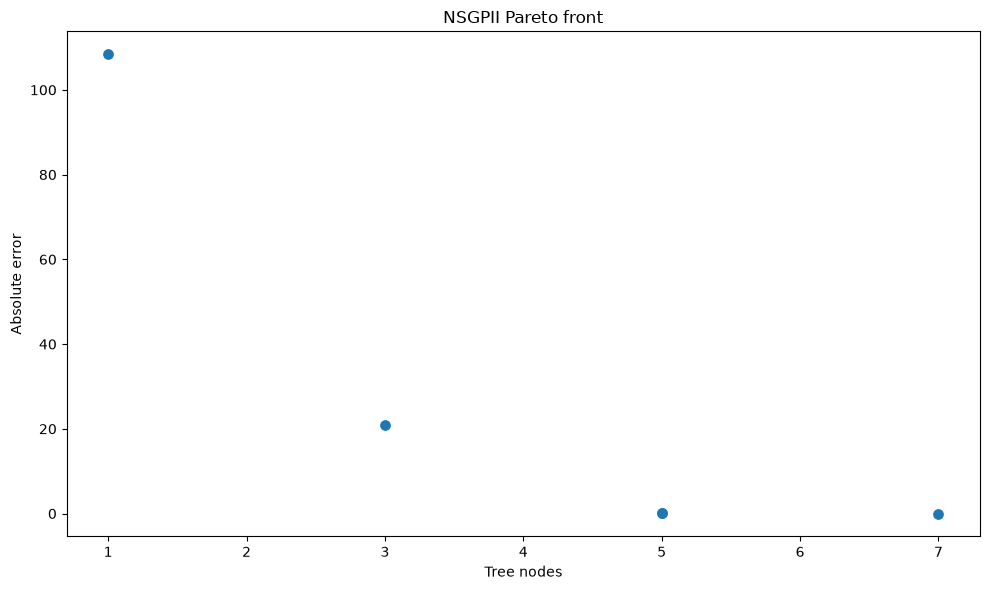

nodes=1, error=108.4: 9.87
nodes=3, error=20.8531: (9.87 * 9.87)
nodes=5, error=0.0274: (9.87 * (8.98 + x_1))
nodes=5, error=0.0274: ((8.98 + x_1) * 9.87)
nodes=7, error=0.0022: ((x_1 - (-7.38 - x_2)) * 7.69)


In [5]:
errors, sizes = front["fitness"].T
plt.figure(figsize=(10, 6))
plt.scatter(sizes, errors, s=45)
plt.xlabel("Tree nodes")
plt.ylabel("Absolute error")
plt.title("NSGPII Pareto front")
plt.tight_layout()
plt.show()

for index in np.argsort(sizes):
    print(f"nodes={int(sizes[index])}, error={errors[index]:.6g}: {front['phenotype'][index]}")

## SelfCNSGPII

Operator selection probabilities adapt during optimization.

In [6]:
adaptive_gp = SelfCNSGPII(
    fitness_function=fitness_function,
    uniset=uniset,
    iters=number_of_generations,
    pop_size=population_size,
    minimization=(True, True),
    init_level=3,
    max_level=3,
    keep_history=True,
    show_progress_each=20,
    random_state=42,
)
adaptive_gp.fit()
adaptive_front = adaptive_gp.get_pareto_front()

0-th iteration with Pareto front size = 4; best objectives = [f1=1.73, f2=3]
20-th iteration with Pareto front size = 3; best objectives = [f1=0.0016, f2=1]
40-th iteration with Pareto front size = 3; best objectives = [f1=0.0016, f2=1]
60-th iteration with Pareto front size = 3; best objectives = [f1=0.0016, f2=1]
80-th iteration with Pareto front size = 4; best objectives = [f1=0, f2=1]


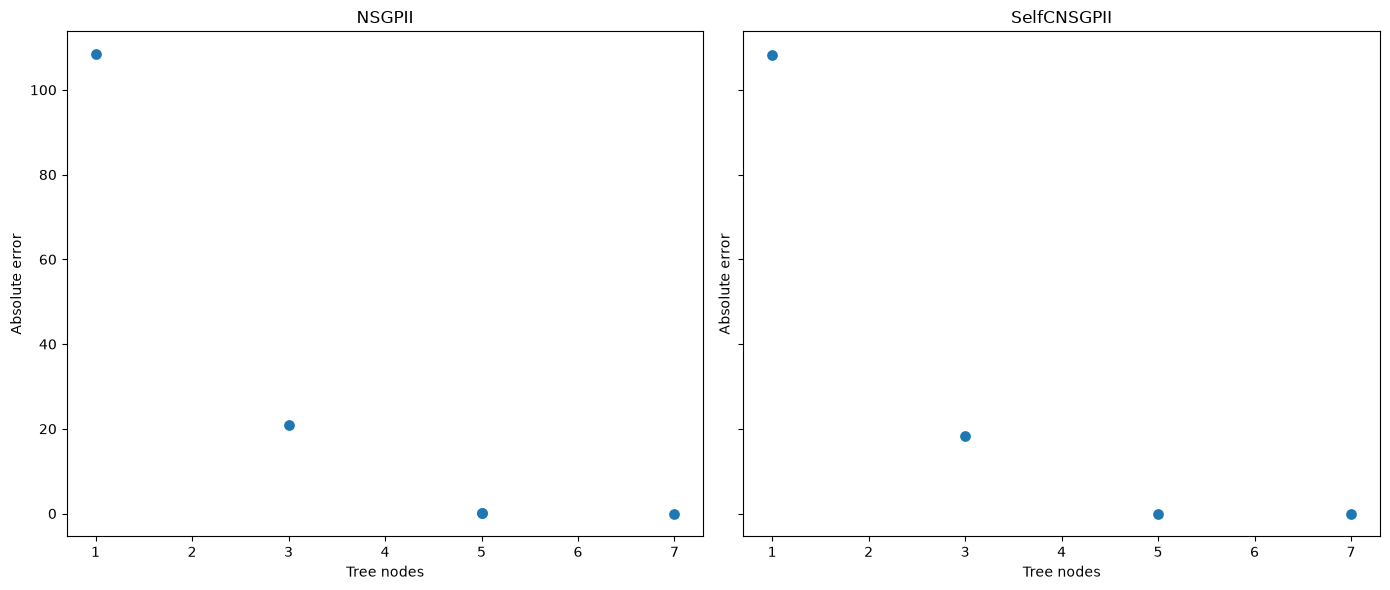

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, result, title in zip(axes, [front, adaptive_front], ["NSGPII", "SelfCNSGPII"]):
    errors, sizes = result["fitness"].T
    ax.scatter(sizes, errors, s=45)
    ax.set(xlabel="Tree nodes", ylabel="Absolute error", title=title)
plt.tight_layout()
plt.show()

## Selected trees from the Pareto front

#1: value=10, target=118.27, formula=10.0
#3: value=99.9, target=118.27, formula=(10.0 * 9.99)
#2: value=118.27, target=118.27, formula=((x_2 * (x_1 * 7.22)) + 9.97)


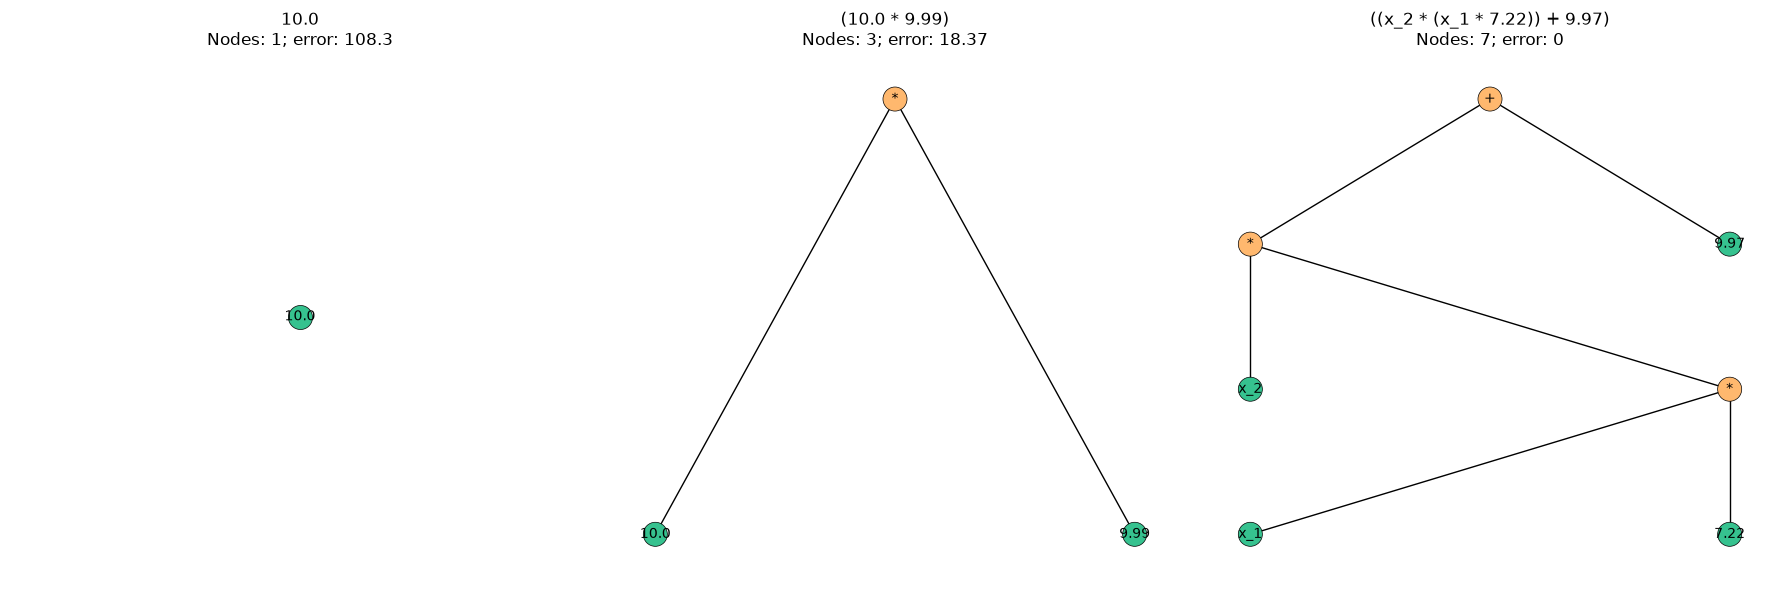

In [8]:
from textwrap import fill

errors, sizes = adaptive_front["fitness"].T
_, unique = np.unique(adaptive_front["fitness"], axis=0, return_index=True)
order = unique[np.argsort(sizes[unique])]
selected = order[np.linspace(0, len(order) - 1, min(3, len(order)), dtype=int)]

fig, axes = plt.subplots(1, len(selected), figsize=(18, 6), squeeze=False)
for ax, index in zip(axes.flat, selected):
    tree = adaptive_front["phenotype"][index]
    tree.plot(ax=ax)
    ax.set_title(fill(str(tree), 40) + f"\nNodes: {int(sizes[index])}; error: {errors[index]:.4g}")
    ax.axis("off")
    print(f"#{index}: value={tree():.6g}, target={target:.6g}, formula={tree}")
plt.tight_layout()
plt.show()

## Operator probabilities and Pareto front size

In [ ]:
stats = adaptive_gp.get_stats()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, key, title in zip(axes.flat, ["s_proba", "c_proba", "m_proba"],
                          ["Selection", "Crossover", "Mutation"]):
    for operator in stats[key][0]:
        ax.plot([step[operator] for step in stats[key]], label=operator)
    ax.set(title=title, ylabel="Probability")
    ax.legend()
axes[1, 1].plot([np.count_nonzero(rank == 1) for rank in stats["pareto_rank"]])
axes[1, 1].set(title="Pareto front size", ylabel="Individuals")
for ax in axes.flat:
    ax.set_xlabel("Generation")
plt.tight_layout()
plt.show()